⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Data ready...
🚀 Running Dual KC(50/49) + RSI(40 Typical) Strategy...

🎯 STRATEGY - Dual KC(50/49) + RSI(40 Typical) STOP Orders
     Final Equity: 20532.8919
     Total Return: 1.0533
    CAGR (approx): 0.3994
     Max Drawdown: -0.0938
           Sharpe: 2.0372
           Trades: 280
          Winrate: 0.4393
    Avg PnL/Trade: 42.7954
    Profit Factor: 1.5227

💡 Estimated R:R: 1:1.94


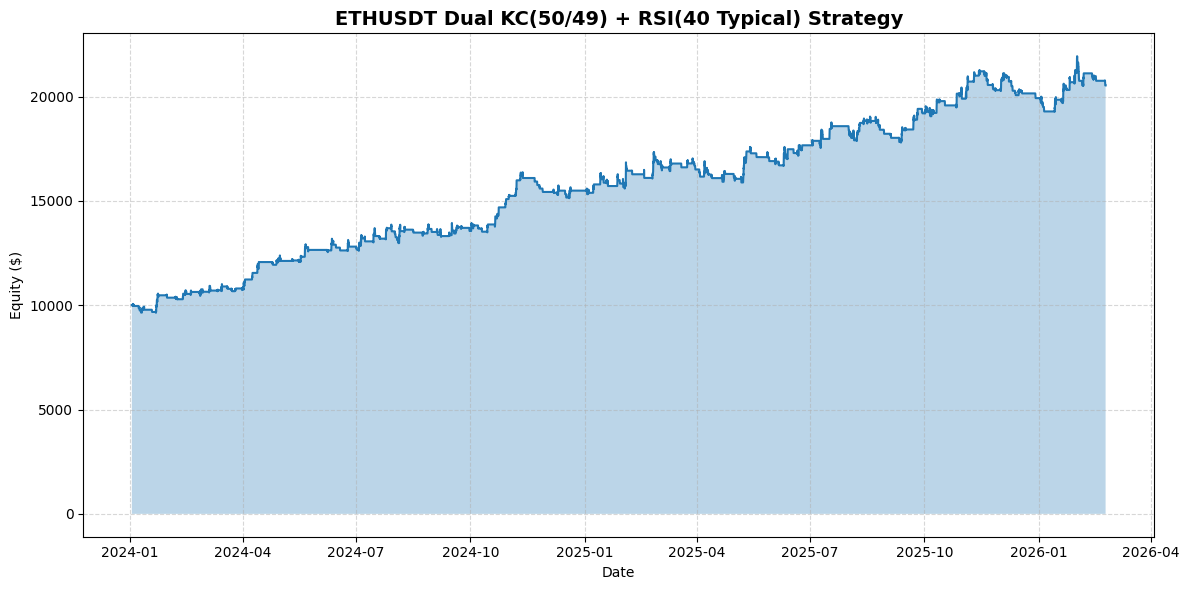


📊 Sample Trades:
            Exit Time   Type        Entry         Exit   Qty   Gross PnL  Exit Fee     Net PnL       Reason       Balance
0 2024-01-04 06:00:00  SHORT  2223.790000  2238.800000  2.15  -32.271500  2.406710  -34.678210    Time Exit   9962.931216
1 2024-01-08 06:00:00  SHORT  2184.958960  2209.379292  4.07  -99.390750  4.496087 -103.886837    Stop Loss   9854.597987
2 2024-01-09 00:00:00   LONG  2335.980000  2303.798625  3.06  -98.475009  3.524812 -101.999820    Stop Loss   9749.024117
3 2024-01-10 02:00:00   LONG  2398.640000  2352.512357  2.11  -97.329327  2.481901  -99.811227    Stop Loss   9646.682325
4 2024-01-11 11:00:00   LONG  2505.085574  2652.694141  1.65  243.554137  2.188473  241.365664  Take Profit   9885.981294
5 2024-01-12 16:00:00   LONG  2680.431930  2628.933432  1.91  -98.362131  2.510631 -100.872763    Stop Loss   9782.548718
6 2024-01-18 22:00:00  SHORT  2439.500000  2468.596908  3.36  -97.765611  4.147243 -101.912854    Stop Loss   9676.537505
7 2024

In [21]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) HÀM TẢI DỮ LIỆU BINANCE
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) HÀM TÍNH INDICATORS (ĐÚNG LOGIC STRATEGY)
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # Typical Price
    data["Typical_Price"] = (data["High"] + data["Low"] + data["Close"]) / 3.0

    # True Range
    prev_close = data["Close"].shift(1)
    data["TR"] = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)

    # ATR (Wilder EMA style)
    def calc_atr(tr: pd.Series, period: int) -> pd.Series:
        return tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_30"] = calc_atr(data["TR"], 30)
    data["ATR_50"] = calc_atr(data["TR"], 50)

    # RSI (SMA rolling mean như template mẫu)
    def calc_rsi(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    # RSI(40) on Typical Price
    data["RSI_40"] = calc_rsi(data["Typical_Price"], 40)

    # Keltner Channel:
    # KC(50, dev=2.5) dùng EMA_50 và ATR_50
    data["EMA_50"] = data["Close"].ewm(span=50, adjust=False).mean()
    data["KC_Upper_50"] = data["EMA_50"] + (2.5 * data["ATR_50"])
    data["KC_Lower_50"] = data["EMA_50"] - (2.5 * data["ATR_50"])

    # KC(49, dev=1.0) dùng EMA_49 và ATR_49
    data["EMA_49"] = data["Close"].ewm(span=49, adjust=False).mean()
    data["ATR_49"] = calc_atr(data["TR"], 49)
    data["KC_Upper_49"] = data["EMA_49"] + (1.0 * data["ATR_49"])
    data["KC_Lower_49"] = data["EMA_49"] - (1.0 * data["ATR_49"])

    # Highest/Lowest Close lookback PeriodParam=14
    data["Highest_Close_14"] = data["Close"].rolling(window=14).max()
    data["Lowest_Close_14"] = data["Close"].rolling(window=14).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (STOP ORDER + EXPIRATION + SL/TP + TIME EXIT)
# =========================================================
class DualKCRSIBacktester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None          # None / 'LONG' / 'SHORT'
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.qty = 0.0

        self.pending_order = None     # {'type','price','sl_dist','tp_dist','expire_idx'}
        self.fee_rate = 0.0005   # 0.1% mỗi chiều (entry và exit)

        # ===== Strategy Parameters (ĐÚNG MÔ TẢ) =====
        self.risk_pct = 0.01              # 1% balance
        self.price_entry_mult = 2     # PriceEntryMult
        self.sl_coef = 1.6                # SL = 1.6 * ATR(20, shift=1)
        self.tp_coef = 4.5                # TP = 4.5 * ATR(30, shift=1)
        self.exit_after_bars = 16         # ExitAfterBars
        self.pending_expiration = 2       # pending sống tối đa 2 bars

        # MM caps (theo mô tả)
        self.mm_max_lots = 100.0
        self.mm_decimals = 2

    def run(self):
        indices = self.df.index

        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # -------------------------------------------------
            # A) QUẢN LÝ LỆNH ĐANG MỞ (SL/TP/Time Exit)
            # -------------------------------------------------
            if self.position is not None:
                bars_held = i - self.entry_bar_idx

                # Time exit
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar["Close"], idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                # SL/TP intrabar
                if self.position == "LONG":
                    if current_bar["Low"] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if current_bar["High"] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                elif self.position == "SHORT":
                    if current_bar["High"] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if current_bar["Low"] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

            # -------------------------------------------------
            # B) QUẢN LÝ PENDING ORDER (EXPIRATION + FILL)
            # -------------------------------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p_price = self.pending_order["price"]

                    # BUY STOP fill nếu High chạm
                    if self.pending_order["type"] == "BUY_STOP" and current_bar["High"] >= p_price:
                        fill_price = max(p_price, current_bar["Open"])  # mô phỏng gap
                        self.open_position(
                            "LONG", fill_price, i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"]
                        )
                        self.pending_order = None

                    # SELL STOP fill nếu Low chạm
                    elif self.pending_order["type"] == "SELL_STOP" and current_bar["Low"] <= p_price:
                        fill_price = min(p_price, current_bar["Open"])  # mô phỏng gap
                        self.open_position(
                            "SHORT", fill_price, i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"]
                        )
                        self.pending_order = None

            # -------------------------------------------------
            # C) TÍN HIỆU VÀO LỆNH (ĐÚNG SHIFT + RULE)
            # -------------------------------------------------
            if self.position is None and self.pending_order is None:
                # cần i>=4 để dùng RSI shift=4 vs shift=3
                # cần i>=3 để dùng Highest/Lowest shift=3 và ATR shift=2
                if i < 4:
                    self.append_equity(idx)
                    continue

                open0 = current_bar["Open"]

                # KC shift=1
                kc_up_50_1 = self.df.iloc[i-1]["KC_Upper_50"]
                kc_lo_50_1 = self.df.iloc[i-1]["KC_Lower_50"]
                kc_up_49_1 = self.df.iloc[i-1]["KC_Upper_49"]
                kc_lo_49_1 = self.df.iloc[i-1]["KC_Lower_49"]

                # RSI shift=4 vs shift=3 (RSI on Typical Price)
                rsi_4 = self.df.iloc[i-4]["RSI_40"]
                rsi_3 = self.df.iloc[i-3]["RSI_40"]

                long_signal = (
                    (open0 > kc_up_50_1) and
                    (rsi_4 < rsi_3) and
                    (open0 > kc_up_49_1)
                )

                short_signal = (
                    (open0 < kc_lo_50_1) and
                    (rsi_4 > rsi_3) and
                    (open0 < kc_lo_49_1)
                )

                if (not long_signal) and (not short_signal):
                    self.append_equity(idx)
                    continue

                # Entry components:
                # Highest/Lowest(CLOSE,14,shift=3) => df.iloc[i-3]
                # ATR(50,shift=2)                 => df.iloc[i-2]
                highest_close_shift3 = self.df.iloc[i-3]["Highest_Close_14"]
                lowest_close_shift3  = self.df.iloc[i-3]["Lowest_Close_14"]
                atr_50_shift2        = self.df.iloc[i-2]["ATR_50"]

                # SL/TP distances (shift=1)
                atr_20_shift1 = self.df.iloc[i-1]["ATR_20"]
                atr_30_shift1 = self.df.iloc[i-1]["ATR_30"]

                sl_distance = self.sl_coef * atr_20_shift1
                tp_distance = self.tp_coef * atr_30_shift1

                # Place pending orders (short only if not long cùng bar)
                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_50_shift2)
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": entry_price,
                        "sl_dist": sl_distance,
                        "tp_dist": tp_distance,
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and (not long_signal):
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_50_shift2)
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": entry_price,
                        "sl_dist": sl_distance,
                        "tp_dist": tp_distance,
                        "expire_idx": i + self.pending_expiration
                    }

            # -------------------------------------------------
            # D) APPEND EQUITY (MARK-TO-MARKET)
            # -------------------------------------------------
            self.append_equity(idx)

    def append_equity(self, idx):
        mark_to_market = self.balance
        close_price = self.df.loc[idx, "Close"]

        if self.position == "LONG":
            mark_to_market += (close_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mark_to_market += (self.entry_price - close_price) * self.qty

        self.equity_curve.append({"time": idx, "equity": mark_to_market})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk-based sizing: 1% balance / SL distance
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        # Clamp + rounding theo mmMaxLots, mmDecimals
        qty = min(qty, self.mm_max_lots)
        qty = np.floor(qty * (10 ** self.mm_decimals)) / (10 ** self.mm_decimals)
        self.qty = float(qty)

        # ===== Trừ phí vào lệnh (ENTRY FEE) =====
        entry_notional = self.entry_price * self.qty
        entry_fee = entry_notional * self.fee_rate
        self.balance -= entry_fee

    def close_position(self, price: float, time_idx, reason: str):
        price = float(price)

        # Gross PnL (chưa trừ phí exit)
        if self.position == "LONG":
            gross_pnl = (price - self.entry_price) * self.qty
        else:
            gross_pnl = (self.entry_price - price) * self.qty

        # Exit fee
        exit_notional = price * self.qty
        exit_fee = exit_notional * self.fee_rate

        # Net PnL sau phí thoát (phí vào đã trừ lúc open)
        net_pnl = gross_pnl - exit_fee

        self.balance += net_pnl

        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "Gross PnL": gross_pnl,
            "Exit Fee": exit_fee,
            "Net PnL": net_pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0

# =========================================================
# 4) METRICS
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    drawdown = (eq_df["equity"] - running_max) / running_max
    max_dd = drawdown.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()

    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df["Net PnL"] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df["Net PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df[trades_df["Net PnL"] > 0]["Net PnL"].sum()
    gross_loss = abs(trades_df[trades_df["Net PnL"] < 0]["Net PnL"].sum())
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "="*60)
    print("🎯 STRATEGY - Dual KC(50/49) + RSI(40 Typical) STOP Orders")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    rr = (metrics["Profit Factor"] * (1 - metrics["Winrate"])) / metrics["Winrate"] if metrics["Winrate"] > 0 else 0
    print(f"\n💡 Estimated R:R: 1:{rr:.2f}")

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)

    plt.title(f"{symbol} Dual KC(50/49) + RSI(40 Typical) Strategy", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "23/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print("✅ Data ready...")
        df_calc = calculate_indicators(df_raw)

        print("🚀 Running Dual KC(50/49) + RSI(40 Typical) Strategy...")
        bt = DualKCRSIBacktester(df_calc, initial_balance=10000.0)
        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades:")
            print(trades_df.head(10).to_string())

            print("\n📈 Exit Reasons:")
            print(trades_df["Reason"].value_counts())
        else:
            print("⚠️ No trades.")
    else:
        print("❌ Insufficient data.")


In [22]:
# Win/Loss flag
trades_df["Win"] = trades_df["Net PnL"] > 0

# Thống kê theo Long/Short
side_stats = trades_df.groupby("Type").agg(
    Total_Trades=("Net PnL", "count"),
    Wins=("Win", "sum"),
    Losses=("Win", lambda x: (~x).sum()),
    Win_Rate=("Win", "mean"),
    Avg_PnL=("Net PnL", "mean"),
    Gross_Profit=("Net PnL", lambda x: x[x > 0].sum()),
    Gross_Loss=("Net PnL", lambda x: abs(x[x < 0].sum()))
)

# Profit Factor theo từng side
side_stats["Profit_Factor"] = side_stats["Gross_Profit"] / side_stats["Gross_Loss"].replace(0, np.nan)

# Đổi Win_Rate sang %
side_stats["Win_Rate"] = side_stats["Win_Rate"] * 100

print("\n📊 Winrate theo từng phía (Long/Short):")
print(side_stats.round(4).to_string())


📊 Winrate theo từng phía (Long/Short):
       Total_Trades  Wins  Losses  Win_Rate  Avg_PnL  Gross_Profit  Gross_Loss  Profit_Factor
Type                                                                                         
LONG            127    56      71   44.0945  38.5806    14728.3969   9828.6613         1.4985
SHORT           153    67      86   43.7908  46.2939    20178.3878  13095.4239         1.5409


⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Data ready...
🚀 Running Dual KC(50/49) + RSI(40 Typical) Strategy...

🎯 STRATEGY - Dual KC(50/49) + RSI(40 Typical) STOP Orders
     Final Equity: 25111.2483
     Total Return: 1.5111
    CAGR (approx): 0.5257
     Max Drawdown: -0.1146
           Sharpe: 1.9954
           Trades: 276
          Winrate: 0.4638
    Avg PnL/Trade: 61.1557
    Profit Factor: 1.6069

💡 Estimated R:R: 1:1.86


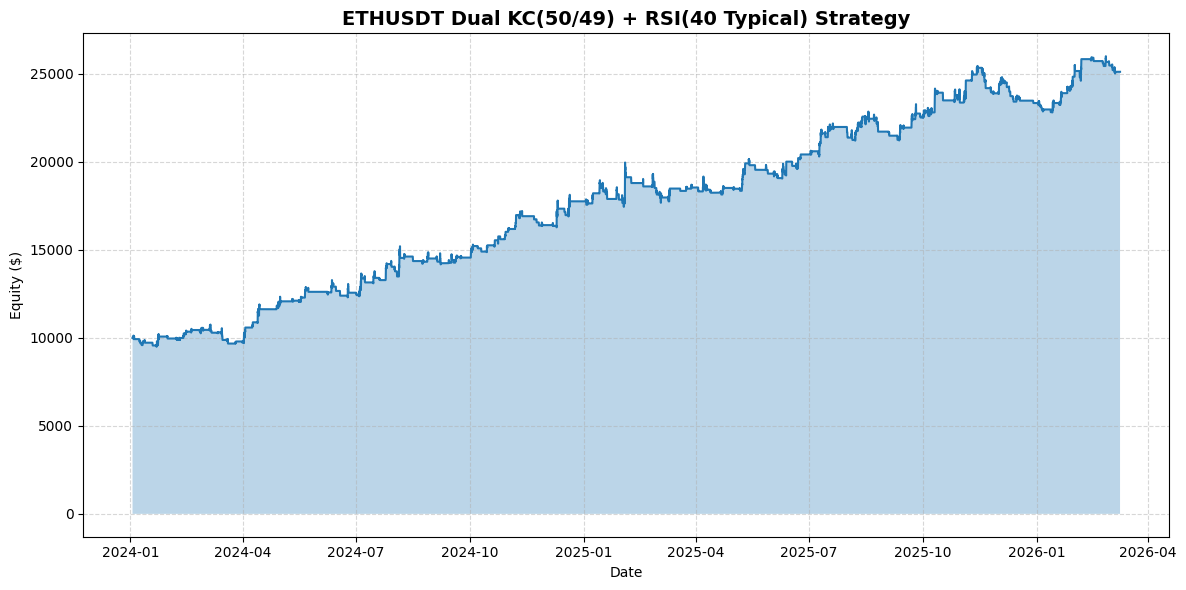


📊 Sample Trades:
            Exit Time   Type        Entry         Exit   Qty   Gross PnL  Exit Fee     Net PnL       Reason       Balance
0 2024-01-04 06:00:00  SHORT  2223.790000  2238.800000  4.30  -64.543000  4.813420  -69.356420    Time Exit   9925.862431
1 2024-01-08 06:00:00  SHORT  2175.529648  2199.949980  5.00 -122.101659  5.499875 -127.601534    Stop Loss   9792.822074
2 2024-01-09 00:00:00   LONG  2335.980000  2303.798625  3.04  -97.831381  3.501774 -101.333155    Stop Loss   9687.938229
3 2024-01-10 02:00:00   LONG  2398.640000  2352.512357  2.10  -96.868051  2.470138  -99.338189    Stop Loss   9586.081469
4 2024-01-11 10:00:00   LONG  2505.081197  2649.102475  1.69  243.395958  2.238492  241.157467  Take Profit   9825.122142
5 2024-01-12 16:00:00   LONG  2680.431930  2628.933432  1.90  -97.847146  2.497487 -100.344633    Stop Loss   9722.231098
6 2024-01-18 22:00:00  SHORT  2439.500000  2468.596908  5.00 -145.484540  6.171492 -151.656032    Stop Loss   9564.476316
7 2024

In [7]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) HÀM TẢI DỮ LIỆU BINANCE
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) HÀM TÍNH INDICATORS (ĐÚNG LOGIC STRATEGY)
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # Typical Price
    data["Typical_Price"] = (data["High"] + data["Low"] + data["Close"]) / 3.0

    # True Range
    prev_close = data["Close"].shift(1)
    data["TR"] = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)

    # ATR (Wilder EMA style)
    def calc_atr(tr: pd.Series, period: int) -> pd.Series:
        return tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_30"] = calc_atr(data["TR"], 30)
    data["ATR_50"] = calc_atr(data["TR"], 50)

    # RSI (SMA rolling mean)
    def calc_rsi(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_40"] = calc_rsi(data["Typical_Price"], 40)

    # Keltner Channel
    data["EMA_50"] = data["Close"].ewm(span=50, adjust=False).mean()
    data["KC_Upper_50"] = data["EMA_50"] + (2.5 * data["ATR_50"])
    data["KC_Lower_50"] = data["EMA_50"] - (2.5 * data["ATR_50"])

    data["EMA_49"] = data["Close"].ewm(span=49, adjust=False).mean()
    data["ATR_49"] = calc_atr(data["TR"], 49)
    data["KC_Upper_49"] = data["EMA_49"] + (1.0 * data["ATR_49"])
    data["KC_Lower_49"] = data["EMA_49"] - (1.0 * data["ATR_49"])

    # Highest/Lowest Close
    data["Highest_Close_14"] = data["Close"].rolling(window=14).max()
    data["Lowest_Close_14"] = data["Close"].rolling(window=14).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (LONG/SHORT PARAMS TÁCH RIÊNG)
# =========================================================
class DualKCRSIBacktester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None          # None / 'LONG' / 'SHORT'
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.qty = 0.0

        # Time exit riêng cho lệnh đang mở
        self.current_exit_after_bars = None

        # Pending order:
        # {'type','price','sl_dist','tp_dist','expire_idx','risk_pct','exit_after_bars'}
        self.pending_order = None

        self.fee_rate = 0.0005   # 0.05% mỗi chiều

        # ===== LONG PARAMS =====
        self.risk_pct_long = 0.01
        self.price_entry_mult_long = 2.0
        self.sl_coef_long = 1.6
        self.tp_coef_long = 4.5
        self.exit_after_bars_long = 16
        self.pending_expiration_long = 2

        # ===== SHORT PARAMS =====
        self.risk_pct_short = 0.01
        self.price_entry_mult_short = 2.6
        self.sl_coef_short = 1.6
        self.tp_coef_short = 4.5
        self.exit_after_bars_short = 16
        self.pending_expiration_short = 2

        # MM caps
        self.mm_max_lots = 5.0
        self.mm_decimals = 2

    def run(self):
        indices = self.df.index

        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # -------------------------------------------------
            # A) QUẢN LÝ LỆNH ĐANG MỞ (SL/TP/Time Exit)
            # -------------------------------------------------
            if self.position is not None:
                bars_held = i - self.entry_bar_idx

                # Time exit theo param của lệnh đang mở
                if self.current_exit_after_bars is not None and bars_held >= self.current_exit_after_bars:
                    self.close_position(current_bar["Close"], idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                # SL/TP intrabar
                if self.position == "LONG":
                    if current_bar["Low"] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if current_bar["High"] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                elif self.position == "SHORT":
                    if current_bar["High"] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if current_bar["Low"] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

            # -------------------------------------------------
            # B) QUẢN LÝ PENDING ORDER (EXPIRATION + FILL)
            # -------------------------------------------------
            if self.position is None and self.pending_order is not None:
                if i > self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p_price = self.pending_order["price"]

                    # BUY STOP fill nếu High chạm
                    if self.pending_order["type"] == "BUY_STOP" and current_bar["High"] >= p_price:
                        fill_price = max(p_price, current_bar["Open"])  # mô phỏng gap
                        self.open_position(
                            "LONG",
                            fill_price,
                            i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"],
                            self.pending_order["risk_pct"],
                            self.pending_order["exit_after_bars"]
                        )
                        self.pending_order = None

                    # SELL STOP fill nếu Low chạm
                    elif self.pending_order["type"] == "SELL_STOP" and current_bar["Low"] <= p_price:
                        fill_price = min(p_price, current_bar["Open"])  # mô phỏng gap
                        self.open_position(
                            "SHORT",
                            fill_price,
                            i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"],
                            self.pending_order["risk_pct"],
                            self.pending_order["exit_after_bars"]
                        )
                        self.pending_order = None

            # -------------------------------------------------
            # C) TÍN HIỆU VÀO LỆNH (ĐÚNG SHIFT + RULE)
            # -------------------------------------------------
            if self.position is None and self.pending_order is None:
                if i < 4:
                    self.append_equity(idx)
                    continue

                open0 = current_bar["Open"]

                # KC shift=1
                kc_up_50_1 = self.df.iloc[i-1]["KC_Upper_50"]
                kc_lo_50_1 = self.df.iloc[i-1]["KC_Lower_50"]
                kc_up_49_1 = self.df.iloc[i-1]["KC_Upper_49"]
                kc_lo_49_1 = self.df.iloc[i-1]["KC_Lower_49"]

                # RSI shift=4 vs shift=3
                rsi_4 = self.df.iloc[i-4]["RSI_40"]
                rsi_3 = self.df.iloc[i-3]["RSI_40"]

                long_signal = (
                    (open0 > kc_up_50_1) and
                    (rsi_4 < rsi_3) and
                    (open0 > kc_up_49_1)
                )

                short_signal = (
                    (open0 < kc_lo_50_1) and
                    (rsi_4 > rsi_3) and
                    (open0 < kc_lo_49_1)
                )

                if (not long_signal) and (not short_signal):
                    self.append_equity(idx)
                    continue

                # Entry components
                highest_close_shift3 = self.df.iloc[i-3]["Highest_Close_14"]
                lowest_close_shift3  = self.df.iloc[i-3]["Lowest_Close_14"]
                atr_50_shift2        = self.df.iloc[i-2]["ATR_50"]

                # SL/TP ATR references (shift=1)
                atr_20_shift1 = self.df.iloc[i-1]["ATR_20"]
                atr_30_shift1 = self.df.iloc[i-1]["ATR_30"]

                # Ưu tiên long nếu cùng bar có cả 2 (giữ đúng logic cũ)
                if long_signal:
                    long_entry_price = highest_close_shift3 + (self.price_entry_mult_long * atr_50_shift2)
                    long_sl_distance = self.sl_coef_long * atr_20_shift1
                    long_tp_distance = self.tp_coef_long * atr_30_shift1

                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": long_entry_price,
                        "sl_dist": long_sl_distance,
                        "tp_dist": long_tp_distance,
                        "expire_idx": i + self.pending_expiration_long,
                        "risk_pct": self.risk_pct_long,
                        "exit_after_bars": self.exit_after_bars_long
                    }

                elif short_signal:
                    short_entry_price = lowest_close_shift3 - (self.price_entry_mult_short * atr_50_shift2)
                    short_sl_distance = self.sl_coef_short * atr_20_shift1
                    short_tp_distance = self.tp_coef_short * atr_30_shift1

                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": short_entry_price,
                        "sl_dist": short_sl_distance,
                        "tp_dist": short_tp_distance,
                        "expire_idx": i + self.pending_expiration_short,
                        "risk_pct": self.risk_pct_short,
                        "exit_after_bars": self.exit_after_bars_short
                    }

            # -------------------------------------------------
            # D) APPEND EQUITY (MARK-TO-MARKET)
            # -------------------------------------------------
            self.append_equity(idx)

    def append_equity(self, idx):
        mark_to_market = self.balance
        close_price = self.df.loc[idx, "Close"]

        if self.position == "LONG":
            mark_to_market += (close_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mark_to_market += (self.entry_price - close_price) * self.qty

        self.equity_curve.append({"time": idx, "equity": mark_to_market})

    def open_position(
        self,
        pos_type: str,
        price: float,
        bar_idx: int,
        sl_dist: float,
        tp_dist: float,
        risk_pct: float,
        exit_after_bars: int
    ):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)
        self.current_exit_after_bars = int(exit_after_bars)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk-based sizing theo param riêng Long/Short
        risk_amount = self.balance * float(risk_pct)
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        # Clamp + rounding
        qty = min(qty, self.mm_max_lots)
        qty = np.floor(qty * (10 ** self.mm_decimals)) / (10 ** self.mm_decimals)
        self.qty = float(qty)

        # Entry fee
        entry_notional = self.entry_price * self.qty
        entry_fee = entry_notional * self.fee_rate
        self.balance -= entry_fee

    def close_position(self, price: float, time_idx, reason: str):
        price = float(price)

        # Gross PnL
        if self.position == "LONG":
            gross_pnl = (price - self.entry_price) * self.qty
        else:
            gross_pnl = (self.entry_price - price) * self.qty

        # Exit fee
        exit_notional = price * self.qty
        exit_fee = exit_notional * self.fee_rate

        # Net PnL (entry fee đã trừ lúc open)
        net_pnl = gross_pnl - exit_fee
        self.balance += net_pnl

        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "Gross PnL": gross_pnl,
            "Exit Fee": exit_fee,
            "Net PnL": net_pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0
        self.current_exit_after_bars = None


# =========================================================
# 4) METRICS
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    drawdown = (eq_df["equity"] - running_max) / running_max
    max_dd = drawdown.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()

    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df["Net PnL"] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df["Net PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df[trades_df["Net PnL"] > 0]["Net PnL"].sum()
    gross_loss = abs(trades_df[trades_df["Net PnL"] < 0]["Net PnL"].sum())
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "="*60)
    print("🎯 STRATEGY - Dual KC(50/49) + RSI(40 Typical) STOP Orders")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    rr = (metrics["Profit Factor"] * (1 - metrics["Winrate"])) / metrics["Winrate"] if metrics["Winrate"] > 0 else 0
    print(f"\n💡 Estimated R:R: 1:{rr:.2f}")

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)

    plt.title(f"{symbol} Dual KC(50/49) + RSI(40 Typical) Strategy", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "09/03/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print("✅ Data ready...")
        df_calc = calculate_indicators(df_raw)

        print("🚀 Running Dual KC(50/49) + RSI(40 Typical) Strategy...")
        bt = DualKCRSIBacktester(df_calc, initial_balance=10000.0)

        # ===== Ví dụ set param riêng LONG/SHORT =====
        # LONG
        bt.risk_pct_long = 0.01
        bt.price_entry_mult_long = 2
        bt.sl_coef_long = 1.6
        bt.tp_coef_long = 4.5
        bt.exit_after_bars_long = 16
        bt.pending_expiration_long = 2

        # SHORT
        bt.risk_pct_short = 0.02
        bt.price_entry_mult_short = 2.6
        bt.sl_coef_short = 1.6
        bt.tp_coef_short = 4.5
        bt.exit_after_bars_short = 16
        bt.pending_expiration_short = 2

        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades:")
            print(trades_df.head(10).to_string())

            print("\n📈 Exit Reasons:")
            print(trades_df["Reason"].value_counts())


        else:
            print("⚠️ No trades.")
    else:
        print("❌ Insufficient data.")

In [2]:
# Win/Loss flag
trades_df["Win"] = trades_df["Net PnL"] > 0

# Thống kê theo Long/Short
side_stats = trades_df.groupby("Type").agg(
    Total_Trades=("Net PnL", "count"),
    Wins=("Win", "sum"),
    Losses=("Win", lambda x: (~x).sum()),
    Win_Rate=("Win", "mean"),
    Avg_PnL=("Net PnL", "mean"),
    Gross_Profit=("Net PnL", lambda x: x[x > 0].sum()),
    Gross_Loss=("Net PnL", lambda x: abs(x[x < 0].sum()))
)

# Profit Factor theo từng side
side_stats["Profit_Factor"] = side_stats["Gross_Profit"] / side_stats["Gross_Loss"].replace(0, np.nan)

# Đổi Win_Rate sang %
side_stats["Win_Rate"] = side_stats["Win_Rate"] * 100

print("\n📊 Winrate theo từng phía (Long/Short):")
print(side_stats.round(4).to_string())


📊 Winrate theo từng phía (Long/Short):
       Total_Trades  Wins  Losses  Win_Rate  Avg_PnL  Gross_Profit  Gross_Loss  Profit_Factor
Type                                                                                         
LONG            141    66      75   46.8085  42.1435    16194.8690  10252.6373         1.5796
SHORT           135    62      73   45.9259  60.5320    18541.7441  10369.9196         1.7880
